In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the RetailPulse project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load cleaned positive-sales data
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "retail_sales.csv"

df = pd.read_csv(DATA_FILE, low_memory=False)

# Convert columns to their proper types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Customer_ID"] = pd.to_numeric(df["Customer_ID"], errors="coerce")

# Check that the data loaded correctly
print("Dataset loaded successfully!")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

display(df.head())
display(df.info())


Dataset loaded successfully!
Rows: 1,007,913
Columns: 13
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country,SourceSheet,IsCancelledInvoice,IsReturnOrNonPositiveQuantity,IsNonPositivePrice,LineValue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,False,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,False,False,False,30.0


<class 'pandas.DataFrame'>
RangeIndex: 1007913 entries, 0 to 1007912
Data columns (total 13 columns):
 #   Column                         Non-Null Count    Dtype         
---  ------                         --------------    -----         
 0   Invoice                        1007913 non-null  str           
 1   StockCode                      1007913 non-null  str           
 2   Description                    1007913 non-null  str           
 3   Quantity                       1007913 non-null  int64         
 4   InvoiceDate                    1007913 non-null  datetime64[us]
 5   Price                          1007913 non-null  float64       
 6   Customer_ID                    779425 non-null   float64       
 7   Country                        1007913 non-null  str           
 8   SourceSheet                    1007913 non-null  str           
 9   IsCancelledInvoice             1007913 non-null  bool          
 10  IsReturnOrNonPositiveQuantity  1007913 non-null  bool          
 

None

In [2]:

# RetailPulse: Key Business Performance Indicators (KPIs)

# Calculate line revenue
df["Revenue"] = df["Quantity"] * df["Price"]

# Calculate key metrics
total_revenue = df["Revenue"].sum()
total_units_sold = df["Quantity"].sum()
unique_products = df["StockCode"].nunique()
unique_customers = df["Customer_ID"].nunique()
unique_invoices = df["Invoice"].nunique()
average_order_value = (
    df.groupby("Invoice")["Revenue"].sum().mean()
)

# Display results
print("========== RETAILPULSE BUSINESS KPIs ==========")
print(f"Total sales revenue: £{total_revenue:,.2f}")
print(f"Total units sold: {total_units_sold:,.0f}")
print(f"Unique products sold: {unique_products:,}")
print(f"Unique identified customers: {unique_customers:,}")
print(f"Unique invoices/orders: {unique_invoices:,}")
print(f"Average revenue per invoice: £{average_order_value:,.2f}")
print("===============================================")


========== RETAILPULSE BUSINESS KPIs ==========
Total sales revenue: £20,476,260.45
Total units sold: 11,205,148
Unique products sold: 4,917
Unique identified customers: 5,878
Unique invoices/orders: 40,077
Average revenue per invoice: £510.92


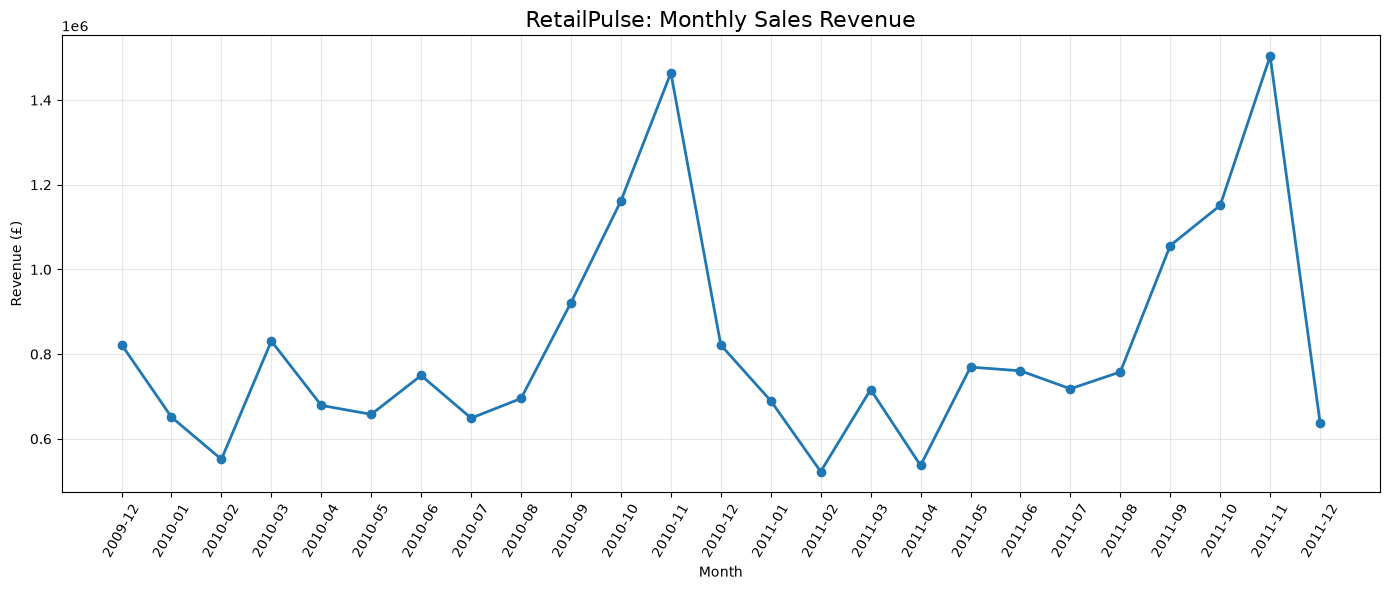

Top 5 months by revenue:


,Revenue (£)
YearMonth,
2011-11,1503866.780
2010-11,1464293.142
2010-10,1161902.220
2011-10,1151263.730
2011-09,1056435.192


In [3]:

# RetailPulse: Monthly Revenue Trend

# Extract year and month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Aggregate revenue by month
monthly_revenue = (
    df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Plot
plt.figure(figsize=(14, 6))
monthly_revenue.index = monthly_revenue.index.astype(str)

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("RetailPulse: Monthly Sales Revenue", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display highest-revenue months
print("Top 5 months by revenue:")
display(
    monthly_revenue.sort_values(ascending=False)
    .head(5)
    .rename("Revenue (£)")
    .to_frame()
)


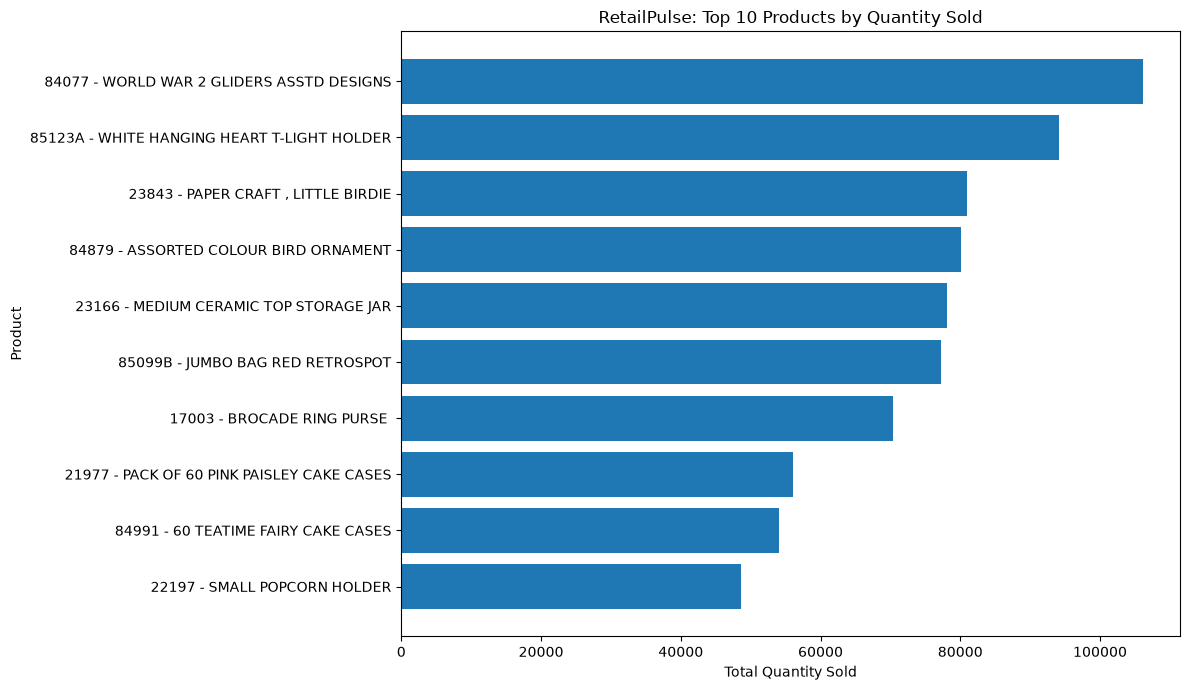

,StockCode,Description,Quantity
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94142
2,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
3,84879,ASSORTED COLOUR BIRD ORNAMENT,80082
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
5,85099B,JUMBO BAG RED RETROSPOT,77280
6,17003,BROCADE RING PURSE,70369
7,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061
8,84991,60 TEATIME FAIRY CAKE CASES,54028
9,22197,SMALL POPCORN HOLDER,48561


In [4]:

# RetailPulse: Top 10 Products by Quantity Sold

top_products = (
    df.groupby(["StockCode", "Description"], dropna=False)["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Create readable product labels
top_products["Product"] = (
    top_products["StockCode"].astype(str)
    + " - "
    + top_products["Description"].fillna("Unknown")
        .astype(str).str.slice(0, 35)
)

plt.figure(figsize=(12, 7))
plt.barh(top_products["Product"], top_products["Quantity"])
plt.title("RetailPulse: Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(top_products[["StockCode", "Description", "Quantity"]])


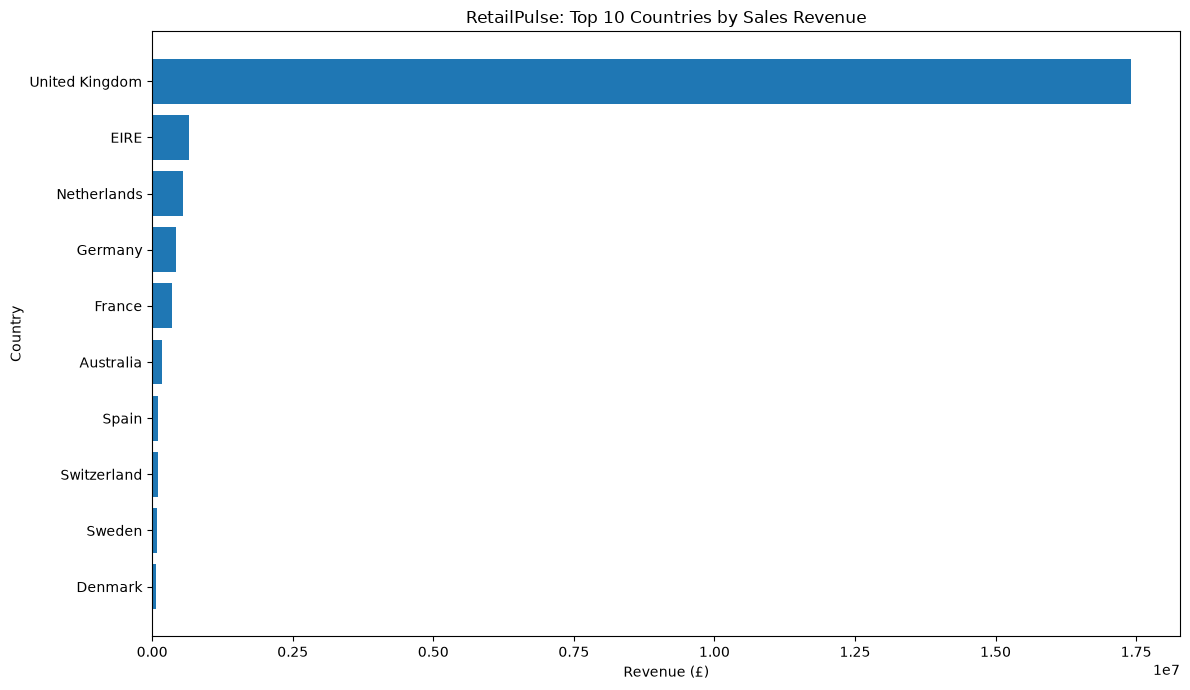

,Revenue (£)
Country,
United Kingdom,1.741020e+07
EIRE,6.587673e+05
Netherlands,5.540381e+05
Germany,4.250197e+05
France,3.504561e+05
Australia,1.692835e+05
Spain,1.083325e+05
Switzerland,1.006856e+05
Sweden,9.186982e+04


In [5]:

# RetailPulse: Revenue by Country

country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

top_countries = country_revenue.head(10)

plt.figure(figsize=(12, 7))
plt.barh(top_countries.index, top_countries.values)
plt.title("RetailPulse: Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(
    top_countries.rename("Revenue (£)").to_frame()
)


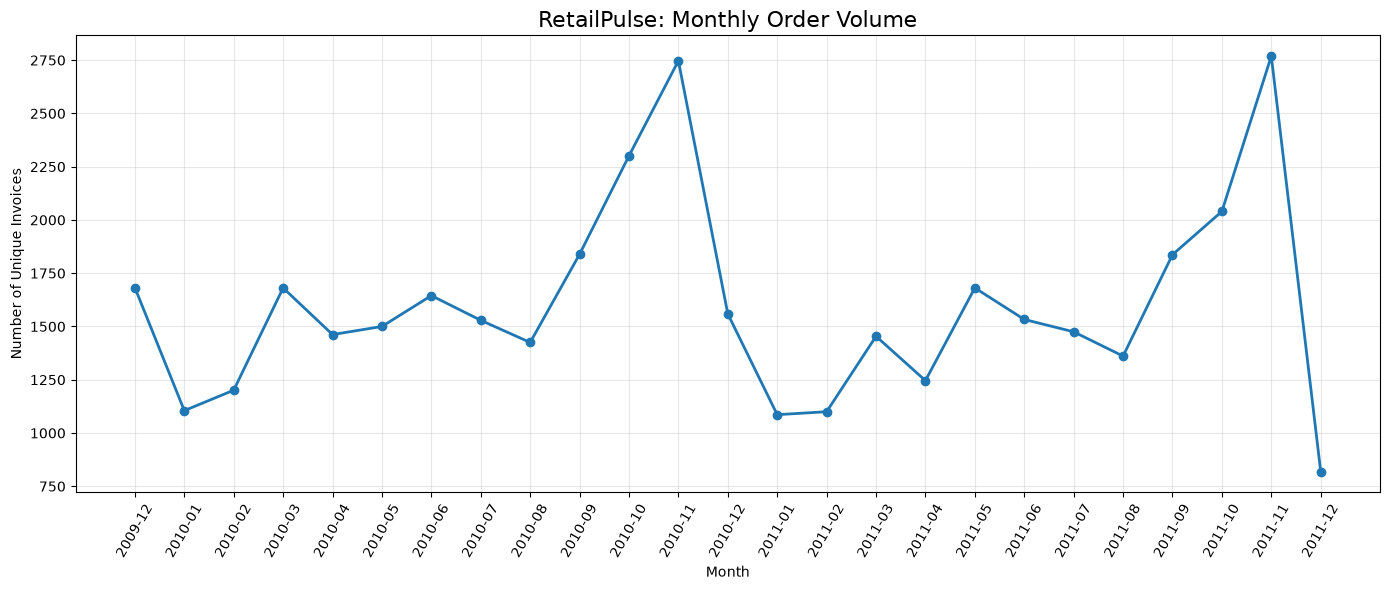

Top 5 months by order volume:


,Unique invoices
YearMonth,
2011-11,2769
2010-11,2747
2010-10,2301
2011-10,2040
2010-09,1839


In [6]:

# RetailPulse: Monthly Order Volume

df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

monthly_orders = (
    df.groupby("YearMonth")["Invoice"]
    .nunique()
    .sort_index()
)

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker="o",
    linewidth=2
)

plt.title("RetailPulse: Monthly Order Volume", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Unique Invoices")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 5 months by order volume:")
display(
    monthly_orders.sort_values(ascending=False)
    .head(5)
    .rename("Unique invoices")
    .to_frame()
)




# Day 2 — Cleaned Data EDA: Key Findings

## 1. Monthly Revenue
- November 2011 recorded the highest revenue: approximately £1.50 million.
- November 2010 was the second-highest month: approximately £1.46 million.
- October also showed strong revenue in both years.

## 2. Product Performance
- World War 2 Gliders Assorted Designs ranked first by quantity sold, with 106,139 units.
- White Hanging Heart T-Light Holder followed with 94,142 units.
- High-volume products are candidates for product-level demand forecasting.

## 3. Country Performance
- The United Kingdom generated approximately £17.41 million in revenue.
- EIRE, the Netherlands, Germany and France were the next-largest markets.
- Revenue concentration suggests the importance of monitoring UK performance.

## 4. Order Volume
- November 2011 recorded 2,769 unique invoices.
- November 2010 recorded 2,747 unique invoices.
- The November peak in orders is consistent with the monthly revenue pattern.

## 5. Data Limitations
- Customer IDs are missing for many transactions.
- Revenue is not profit because product costs and operating expenses are unavailable.
- The current positive-sales dataset excludes cancellations, non-positive quantities and non-positive prices.
- Results require validation before they are treated as final business metrics.

## 6. RetailPulse Applications
- Monthly revenue analysis supports sales monitoring.
- Product quantities support demand forecasting.
- Country performance supports market analysis.
- Customer-level analysis will require filtering for valid customer IDs.


In [7]:

from pathlib import Path
import json
import pandas as pd

# Locate project root
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

# Load saved outputs
transactions = pd.read_csv(
    OUTPUT_DIR / "retail_transactions_cleaned.csv",
    low_memory=False
)
sales = pd.read_csv(
    OUTPUT_DIR / "retail_sales.csv",
    low_memory=False
)

with open(OUTPUT_DIR / "cleaning_report.json", encoding="utf-8") as f:
    report = json.load(f)

# Validation checks
duplicate_columns = [
    col for col in transactions.columns
    if col not in {
        "SourceSheet",
        "IsCancelledInvoice",
        "IsReturnOrNonPositiveQuantity",
        "IsNonPositivePrice",
        "LineValue",
    }
]

checks = {
    "Transaction row count matches report":
        len(transactions) == report["rows_after_duplicate_removal"],

    "Sales row count matches report":
        len(sales) == report["valid_sales_rows"],

    "No duplicate transactions remain":
        not transactions.duplicated(
            subset=duplicate_columns
        ).any(),

    "No cancelled invoices in sales":
        not sales["IsCancelledInvoice"].astype(bool).any(),

    "All sales quantities are positive":
        (pd.to_numeric(sales["Quantity"]) > 0).all(),

    "All sales prices are positive":
        (pd.to_numeric(sales["Price"]) > 0).all(),

    "All sales dates are valid":
        pd.to_datetime(sales["InvoiceDate"], errors="coerce").notna().all(),

    "Sales revenue matches report":
        abs(
            pd.to_numeric(sales["LineValue"]).sum()
            - report["sales_revenue_before_customer_filter"]
        ) < 0.02,
}

print("=== RETAILPULSE DATA VALIDATION ===")
for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {check}")

print("\nTransaction rows:", f"{len(transactions):,}")
print("Sales rows:", f"{len(sales):,}")
print("Missing customer IDs in sales:",
      f"{sales['Customer_ID'].isna().sum():,}")

if all(checks.values()):
    print("\nAll validation checks passed.")
else:
    print("\nSome checks failed. Review them before committing.")


=== RETAILPULSE DATA VALIDATION ===
PASS: Transaction row count matches report
PASS: Sales row count matches report
PASS: No duplicate transactions remain
PASS: No cancelled invoices in sales
PASS: All sales quantities are positive
PASS: All sales prices are positive
PASS: All sales dates are valid
PASS: Sales revenue matches report

Transaction rows: 1,033,036
Sales rows: 1,007,913
Missing customer IDs in sales: 228,488

All validation checks passed.
